#### **IMPLEMENTASI PYTHON PADA DISTRIBUSI PROBABILITAS**

In [ ]:
import math, itertools, random
import statistics as stat
from fractions import Fraction
from collections import Counter
import sympy as sp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st

rng = np.random.default_rng(42)
pd.options.display.float_format = "{:.4f}".format

def info(teks):
    print("\nInterpretasi:", teks)

#### **BAGIAN A. DISTRIBUSI DISKRIT**

#### MATERI A1 - Distribusi Hipergeometrik
#### Studi kasus: memilih 6 dari 12 server yang 2 di antaranya rusak
**Soal:** Sebuah klaster memiliki N = 12 server dan k = 2 di antaranya rusak. Manajemen memilih secara acak n = 6 server (tanpa pengembalian) untuk dipantau. Hitung peluang terpilihnya 2, 1, atau 0 server rusak, serta nilai harapan dan varians.

Rumus: f(x) = C(k,x) C(N-k, n-x) / C(N,n), E(X) = nk/N, Var(X) = n (k/N)(1 - k/N)(N-n)/(N-1).

x = 2: scipy = 0.2273 | manual = 0.2273
x = 1: scipy = 0.5455 | manual = 0.5455
x = 0: scipy = 0.2273 | manual = 0.2273

E(X) scipy = 1.0000 | rumus nk/N = 1.0000
Pecahan eksak P(X=2) = 5/22 = 0.2273
Var(X) scipy = 0.4545 | rumus = 0.4545
Simulasi P(x): {0: 0.2275, 1: 0.5462, 2: 0.2263}

Tambahan: audit 5 dari 50 file yang memuat 8 file berbug -> P(minimal 1 bug ketemu) = 0.5985


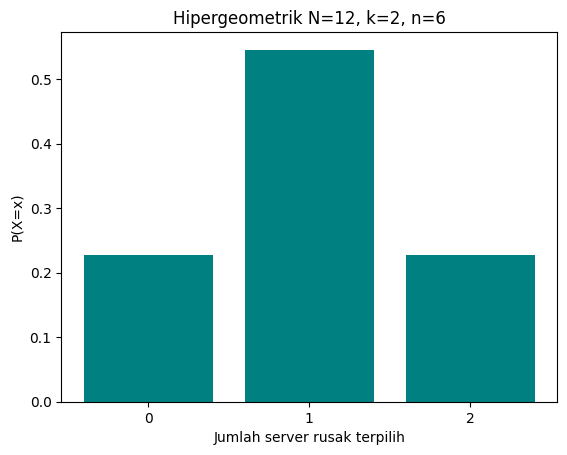


Interpretasi: Peluang tepat 1 server rusak terpilih 54.5%, sedangkan 0 atau 2 masing-masing 22.7%.
Rata-rata server rusak dalam sampel 1.

Pada audit file, memeriksa 5 dari 50 file hanya menemukan minimal satu file berbug dengan peluang 60%,
sehingga sampel sekecil itu kurang layak untuk menjamin kualitas.


In [ ]:
N, k, n = 12, 2, 6
H = st.hypergeom(M=N, n=k, N=n)

for x in [2, 1, 0]:
    manual = math.comb(k, x) * math.comb(N - k, n - x) / math.comb(N, n)
    print(f"x = {x}: scipy = {H.pmf(x):.4f} | manual = {manual:.4f}")

print(f"\nE(X) scipy = {H.mean():.4f} | rumus nk/N = {n*k/N:.4f}")
eksak = Fraction(math.comb(k, 2) * math.comb(N - k, n - 2), math.comb(N, n))
print(f"Pecahan eksak P(X=2) = {eksak} = {float(eksak):.4f}")
var_rumus = n * (k / N) * (1 - k / N) * (N - n) / (N - 1)
print(f"Var(X) scipy = {H.var():.4f} | rumus = {var_rumus:.4f}")

sim = rng.hypergeometric(ngood=k, nbad=N - k, nsample=n, size=100000)
print("Simulasi P(x):", {x: round(float((sim == x).mean()), 4) for x in [0, 1, 2]})

# Kasus tambahan: audit file
M, bug, sampel = 50, 8, 5
p_min1 = 1 - st.hypergeom(M, bug, sampel).pmf(0)
print(f"\nTambahan: audit {sampel} dari {M} file yang memuat {bug} file berbug -> P(minimal 1 bug ketemu) = {p_min1:.4f}")

xs = np.arange(0, 3)
plt.bar(xs, H.pmf(xs), color="teal")
plt.xticks(xs); plt.title("Hipergeometrik N=12, k=2, n=6"); plt.xlabel("Jumlah server rusak terpilih"); plt.ylabel("P(X=x)")
plt.show()

info(f"""Peluang tepat 1 server rusak terpilih {H.pmf(1):.1%}, sedangkan 0 atau 2 masing-masing {H.pmf(0):.1%}.
Rata-rata server rusak dalam sampel {H.mean():.0f}.

Pada audit file, memeriksa 5 dari 50 file hanya menemukan minimal satu file berbug dengan peluang {p_min1:.0%},
sehingga sampel sekecil itu kurang layak untuk menjamin kualitas.""")

#### MATERI A2 - Distribusi Binomial
#### Studi kasus: server A terpilih maintenance dalam 5 hari dan error request
**Soal 1:** Setiap hari selama 5 hari, sistem memilih secara acak 1 dari 4 server (A, B, C, D) untuk maintenance, dengan peluang sama. Berapa peluang server A terpilih tepat 3 kali? Berapa peluang untuk 0 sampai 5 kali?
**Soal 2:** Dari 20 request, peluang tiap request error adalah 0,05. Berapa peluang terdapat paling sedikit 2 error?

Rumus: f(x) = C(n,x) p^x (1-p)^(n-x), E(X) = np, Var(X) = npq, skewness = (q-p)/sqrt(npq).

 x  P(X=x)  P(X<=x)
 0  0.2373   0.2373
 1  0.3955   0.6328
 2  0.2637   0.8965
 3  0.0879   0.9844
 4  0.0146   0.9990
 5  0.0010   1.0000

P(X=3) = 0.0879 (manual: 10 x 0.25^3 x 0.75^2 = 0.0879)
E(X) = 1.2500 | Var(X) = 0.9375 | skewness = 0.5164
Enumerasi itertools: 10 urutan memuat A tepat 3 kali -> P = 10 x p^3 x q^2 = 0.0879
Simulasi: P(X=3) = 0.0873 | mean = 1.2451
Frekuensi simulasi (Counter): [(0, 23862), (1, 39741), (2, 26094), (3, 8732), (4, 1471), (5, 100)]

Soal 2: P(X>=2) = 1 - P(X<=1) = 0.2642


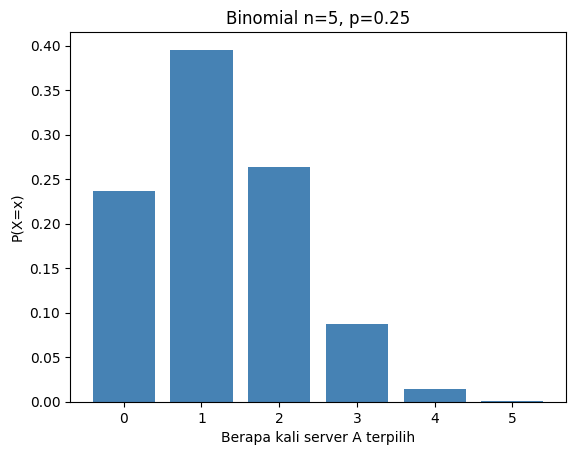


Interpretasi: Peluang server A terpilih tepat 3 kali dalam 5 hari adalah 8.79%.
Rata-rata terpilih 1.25 kali per 5 hari (wajar karena 5 x 1/4).
Skewness positif (0.52) karena q > p sehingga grafik miring ke kanan.

Pada Soal 2, peluang minimal 2 request error dari 20 adalah 26.4%, artinya sekitar 1 dari 4 batch berisi 20 request akan memuat dua error atau lebih, walau tingkat error tiap request hanya 5%.


In [ ]:
n, p = 5, 0.25
B = st.binom(n, p)
tb = pd.DataFrame({"x": range(n + 1), "P(X=x)": B.pmf(range(n + 1)), "P(X<=x)": B.cdf(range(n + 1))})
print(tb.to_string(index=False))
print(f"\nP(X=3) = {B.pmf(3):.4f} (manual: {math.comb(5,3)} x 0.25^3 x 0.75^2 = {math.comb(5,3)*0.25**3*0.75**2:.4f})")
q = 1 - p
print(f"E(X) = {B.mean():.4f} | Var(X) = {B.var():.4f} | skewness = {(q-p)/math.sqrt(n*p*q):.4f}")

# Cek dengan enumerasi semua urutan hari (itertools): 2^5 = 32 urutan, 1 = server A terpilih
urutan_3 = [u for u in itertools.product([0, 1], repeat=n) if sum(u) == 3]
print(f"Enumerasi itertools: {len(urutan_3)} urutan memuat A tepat 3 kali -> P = {len(urutan_3)} x p^3 x q^2 = {len(urutan_3) * p**3 * (1-p)**2:.4f}")

sim = rng.binomial(n, p, 100000)
print(f"Simulasi: P(X=3) = {(sim==3).mean():.4f} | mean = {sim.mean():.4f}")
print("Frekuensi simulasi (Counter):", sorted(Counter(sim.tolist()).items()))

# Soal 2
B2 = st.binom(20, 0.05)
p_ge2 = 1 - B2.cdf(1)
print(f"\nSoal 2: P(X>=2) = 1 - P(X<=1) = {p_ge2:.4f}")

plt.bar(range(n + 1), B.pmf(range(n + 1)), color="steelblue")
plt.title("Binomial n=5, p=0.25"); plt.xlabel("Berapa kali server A terpilih"); plt.ylabel("P(X=x)")
plt.show()

info(f"""Peluang server A terpilih tepat 3 kali dalam 5 hari adalah {B.pmf(3):.2%}.
Rata-rata terpilih {B.mean():.2f} kali per 5 hari (wajar karena 5 x 1/4).
Skewness positif ({(q-p)/math.sqrt(n*p*q):.2f}) karena q > p sehingga grafik miring ke kanan.

Pada Soal 2, peluang minimal 2 request error dari 20 adalah {p_ge2:.1%}, artinya sekitar 1 dari 4 batch berisi 20 request akan memuat dua error atau lebih, walau tingkat error tiap request hanya 5%.""")

#### MATERI A3 - Distribusi Geometrik
#### Studi kasus: percobaan koneksi ke server sibuk
**Soal:** Sebuah klien mencoba terhubung ke server yang sibuk. Peluang koneksi berhasil pada tiap percobaan adalah 0,2. Berapa peluang koneksi pertama berhasil pada percobaan ke-4? Berapa peluang berhasil dalam 5 percobaan atau kurang? Berapa rata-rata percobaan?

Rumus: f(x) = (1-p)^(x-1) p, x = 1, 2, 3, ...; E(X) = 1/p; Var(X) = (1-p)/p^2.

P(X=4)  = 0.1024 (manual: 0.8^3 x 0.2 = 0.1024)
P(X<=5) = 0.6723 (manual: 1 - 0.8^5 = 0.6723)
E(X) = 5.00 | Var(X) = 20.00
Simulasi Python murni (random + statistics): mean = 4.982 | varians = 19.674
Simulasi: mean = 5.017 | varians = 20.293


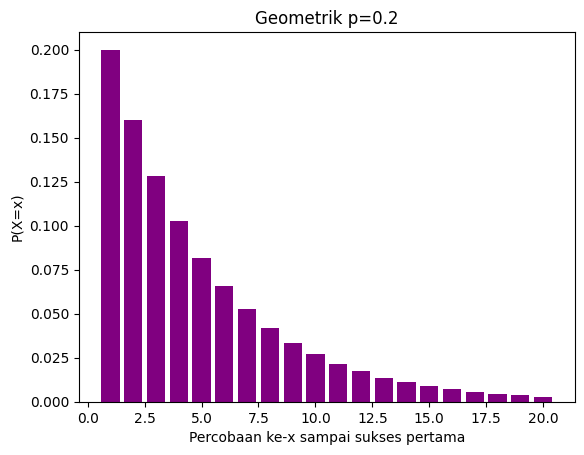


Interpretasi: Peluang baru berhasil pada percobaan ke-4 adalah 10.24%.
Dalam 5 percobaan, peluang sudah berhasil 67.2%.
Rata-rata dibutuhkan 5 percobaan, dengan varians besar (20), yaitu jumlah percobaan sangat bervariasi.
Implikasinya, klien perlu retry mekanisme dengan batas (misalnya 10 kali) agar tidak menunggu terlalu lama.


In [ ]:
p = 0.2
G = st.geom(p)
print(f"P(X=4)  = {G.pmf(4):.4f} (manual: 0.8^3 x 0.2 = {0.8**3*0.2:.4f})")
print(f"P(X<=5) = {G.cdf(5):.4f} (manual: 1 - 0.8^5 = {1-0.8**5:.4f})")
print(f"E(X) = {G.mean():.2f} | Var(X) = {G.var():.2f}")

def percobaan_sampai_sukses(p):
    n = 1
    while random.random() >= p:
        n += 1
    return n
random.seed(1)
sim_py = [percobaan_sampai_sukses(p) for _ in range(20000)]
print(f"Simulasi Python murni (random + statistics): mean = {stat.mean(sim_py):.3f} | varians = {stat.pvariance(sim_py):.3f}")

sim = rng.geometric(p, 100000)
print(f"Simulasi: mean = {sim.mean():.3f} | varians = {sim.var():.3f}")

xs = np.arange(1, 21)
plt.bar(xs, G.pmf(xs), color="purple")
plt.title("Geometrik p=0.2"); plt.xlabel("Percobaan ke-x sampai sukses pertama"); plt.ylabel("P(X=x)")
plt.show()

info(f"""Peluang baru berhasil pada percobaan ke-4 adalah {G.pmf(4):.2%}.
Dalam 5 percobaan, peluang sudah berhasil {G.cdf(5):.1%}.
Rata-rata dibutuhkan {G.mean():.0f} percobaan, dengan varians besar ({G.var():.0f}), yaitu jumlah percobaan sangat bervariasi.
Implikasinya, klien perlu retry mekanisme dengan batas (misalnya 10 kali) agar tidak menunggu terlalu lama.""")

#### MATERI A4 - Distribusi Binomial Negatif
#### Studi kasus: jumlah test case sampai 3 bug ditemukan
**Soal:** Seorang QA harus menemukan r = 3 bug. Tiap test case menemukan bug dengan peluang 0,3. Misalkan X = banyak test case yang dijalankan sampai bug ke-3 ditemukan. Hitung P(X=8), P(X<=10), E(X), dan Var(X).

Rumus (X = jumlah percobaan): f(x) = C(x-1, r-1) p^r (1-p)^(x-r), x = r, r+1, ...; E(X) = r/p; Var(X) = r(1-p)/p^2.
Catatan: `scipy.stats.nbinom` menghitung banyaknya gagal sebelum sukses ke-r, sehingga X = gagal + r.

P(X=8)  scipy = 0.0953 | manual = 0.0953
P(X<=10) = 0.6172
E(X) = 10.00 (rumus r/p = 10.00)
Var(X) = 23.33 (rumus r(1-p)/p^2 = 23.33)
Simulasi: mean = 10.012 | varians = 23.326


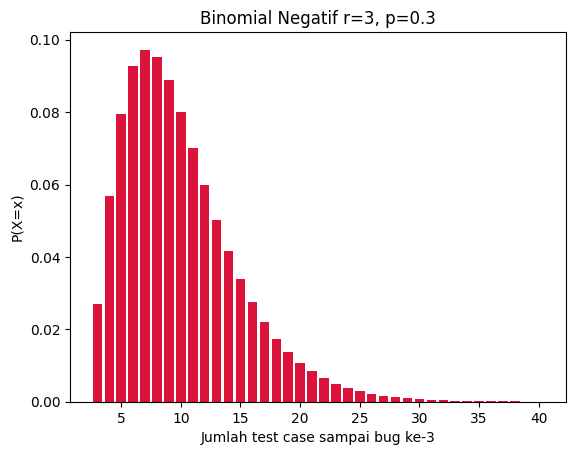


Interpretasi: Rata-rata dibutuhkan 10 test case untuk menemukan 3 bug (3 / 0,3).
Peluang tepat 8 test case adalah 9.53%, dan peluang selesai dalam 10 test case 61.7%.
Jadi sekitar 38% kasus QA perlu lebih dari 10 test case; rencana pengujian harus memberi cadangan waktu.


In [ ]:
r, p = 3, 0.3
NB = st.nbinom(r, p)
x = 8
manual = math.comb(x - 1, r - 1) * p**r * (1 - p) ** (x - r)
print(f"P(X=8)  scipy = {NB.pmf(x - r):.4f} | manual = {manual:.4f}")
print(f"P(X<=10) = {NB.cdf(10 - r):.4f}")
print(f"E(X) = {NB.mean() + r:.2f} (rumus r/p = {r/p:.2f})")
print(f"Var(X) = {NB.var():.2f} (rumus r(1-p)/p^2 = {r*(1-p)/p**2:.2f})")

sim = rng.negative_binomial(r, p, 100000) + r
print(f"Simulasi: mean = {sim.mean():.3f} | varians = {sim.var():.3f}")

xs = np.arange(r, 41)
plt.bar(xs, NB.pmf(xs - r), color="crimson")
plt.title("Binomial Negatif r=3, p=0.3"); plt.xlabel("Jumlah test case sampai bug ke-3"); plt.ylabel("P(X=x)")
plt.show()

info(f"""Rata-rata dibutuhkan {r/p:.0f} test case untuk menemukan 3 bug (3 / 0,3).
Peluang tepat 8 test case adalah {manual:.2%}, dan peluang selesai dalam 10 test case {NB.cdf(10-r):.1%}.
Jadi sekitar {1-NB.cdf(10-r):.0%} kasus QA perlu lebih dari 10 test case; rencana pengujian harus memberi cadangan waktu.""")

#### MATERI A5 - Distribusi Poisson
#### Studi kasus: request per detik pada server dan kapasitasnya
**Soal:** Sebuah server rata-rata menerima λ = 4 request per detik. Kapasitasnya 8 request per detik. Hitung P(X=6), P(X>8) (kelebihan beban), dan peluang dalam 5 detik menerima 30 request atau lebih.

Rumus: f(x) = e^(-λ) λ^x / x!, E(X) = Var(X) = λ.

P(X=6)  = 0.1042 (manual: e^-4 x 4^6 / 6! = 0.1042)
P(X>8)  = 1 - P(X<=8) = 0.0214
E(X) = 4.0 | Var(X) = 4.0
5 detik (lambda=20): P(X>=30) = 0.0218
Simulasi: P(X=6) = 0.1019 | P(X>8) = 0.0216 | mean = 3.991 | var = 4.014


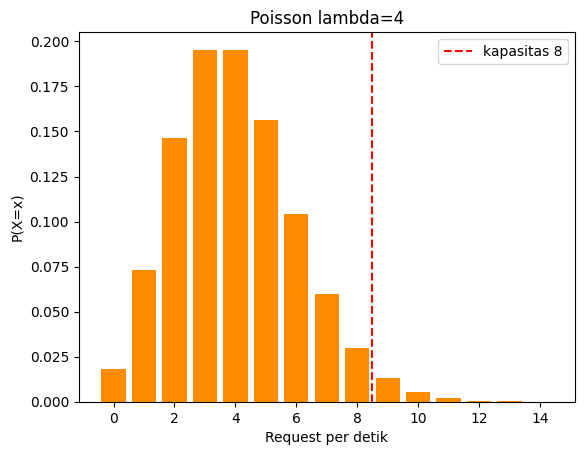


Interpretasi: Peluang tepat 6 request dalam 1 detik adalah 10.42%.
Peluang melampaui kapasitas (lebih dari 8 request/detik) hanya 2.14%, atau sekitar 1 detik dari 47 detik.
Rata-rata dan varians sama (4), ciri khas Poisson, dan cocok dengan simulasi.
Untuk jendela 5 detik, peluang 30 request atau lebih hanya 2.2%, sehingga kapasitas saat ini cukup layak.


In [ ]:
lam = 4
P = st.poisson(lam)
print(f"P(X=6)  = {P.pmf(6):.4f} (manual: e^-4 x 4^6 / 6! = {math.exp(-4)*4**6/math.factorial(6):.4f})")
print(f"P(X>8)  = 1 - P(X<=8) = {P.sf(8):.4f}")
print(f"E(X) = {P.mean():.1f} | Var(X) = {P.var():.1f}")

P5 = st.poisson(lam * 5)
print(f"5 detik (lambda=20): P(X>=30) = {P5.sf(29):.4f}")

sim = rng.poisson(lam, 100000)
print(f"Simulasi: P(X=6) = {(sim==6).mean():.4f} | P(X>8) = {(sim>8).mean():.4f} | mean = {sim.mean():.3f} | var = {sim.var():.3f}")

xs = np.arange(0, 15)
plt.bar(xs, P.pmf(xs), color="darkorange")
plt.axvline(8.5, color="red", linestyle="--", label="kapasitas 8")
plt.title("Poisson lambda=4"); plt.xlabel("Request per detik"); plt.ylabel("P(X=x)"); plt.legend()
plt.show()

info(f"""Peluang tepat 6 request dalam 1 detik adalah {P.pmf(6):.2%}.
Peluang melampaui kapasitas (lebih dari 8 request/detik) hanya {P.sf(8):.2%}, atau sekitar 1 detik dari {round(1/P.sf(8))} detik.
Rata-rata dan varians sama (4), ciri khas Poisson, dan cocok dengan simulasi.
Untuk jendela 5 detik, peluang 30 request atau lebih hanya {P5.sf(29):.1%}, sehingga kapasitas saat ini cukup layak.""")

#### MATERI A6 - Distribusi Multinomial
#### Studi kasus: komposisi trafik Web, API, dan Mobile
**Soal:** Trafik sebuah layanan terdiri dari Web (50%), API (30%), dan Mobile (20%). Dari 10 request, berapa peluang tepat 5 Web, 3 API, dan 2 Mobile? Hitung juga nilai harapan dan varians tiap kategori.

Rumus: f(x1, x2, x3) = n! / (x1! x2! x3!) p1^x1 p2^x2 p3^x3.

In [ ]:
n, ps = 10, [0.5, 0.3, 0.2]
M = st.multinomial(n, ps)
x = [5, 3, 2]
manual = math.factorial(10) / (math.factorial(5) * math.factorial(3) * math.factorial(2)) * 0.5**5 * 0.3**3 * 0.2**2
print(f"P(5,3,2) scipy = {M.pmf(x):.5f} | manual = {manual:.5f}")

semua = [c for c in itertools.product(range(n + 1), repeat=3) if sum(c) == n]
print(f"Jumlah komposisi (x1,x2,x3) dengan total {n}: {len(semua)} | jumlah seluruh peluang = {sum(M.pmf(list(c)) for c in semua):.4f}")

kat = ["Web", "API", "Mobile"]
tb = pd.DataFrame({"Kategori": kat, "p": ps, "E(Xi) = n.p": [n * p for p in ps], "Var(Xi) = n.p.(1-p)": [n * p * (1 - p) for p in ps]})
print(tb.to_string(index=False))

sim = rng.multinomial(n, ps, size=100000)
print("\nSimulasi rata-rata per kategori:", sim.mean(axis=0).round(3))
print(f"Simulasi P(5,3,2) = {(sim == x).all(axis=1).mean():.5f}")
print("Korelasi Web vs API (negatif karena total tetap 10):", round(np.corrcoef(sim[:, 0], sim[:, 1])[0, 1], 3))

info(f"""Peluang komposisi persis 5-3-2 adalah {M.pmf(x):.2%}.
Angkanya kecil karena ada banyak komposisi lain yang mungkin, bukan karena komposisi ini janggal.
Rata-rata tiap kategori mengikuti n x p (5, 3, 2), dan antar kategori berkorelasi negatif: jika Web banyak, API dan Mobile otomatis berkurang.""")

P(5,3,2) scipy = 0.08505 | manual = 0.08505
Jumlah komposisi (x1,x2,x3) dengan total 10: 66 | jumlah seluruh peluang = 1.0000
Kategori      p  E(Xi) = n.p  Var(Xi) = n.p.(1-p)
     Web 0.5000       5.0000               2.5000
     API 0.3000       3.0000               2.1000
  Mobile 0.2000       2.0000               1.6000

Simulasi rata-rata per kategori: [5.006 3.001 1.994]
Simulasi P(5,3,2) = 0.08639
Korelasi Web vs API (negatif karena total tetap 10): -0.655

Interpretasi: Peluang komposisi persis 5-3-2 adalah 8.50%.
Angkanya kecil karena ada banyak komposisi lain yang mungkin, bukan karena komposisi ini janggal.
Rata-rata tiap kategori mengikuti n x p (5, 3, 2), dan antar kategori berkorelasi negatif: jika Web banyak, API dan Mobile otomatis berkurang.


#### **BAGIAN B. DISTRIBUSI KONTINU**

#### MATERI B1 - Distribusi Eksponensial
#### Studi kasus: waktu antar request (keluarga proses Poisson)
**Soal:** Request tiba dengan laju λ = 4 per detik (proses Poisson). Waktu antar request T berdistribusi eksponensial. Hitung P(T>0,5 detik), P(T<0,1 detik), median, dan buktikan sifat tanpa memori: P(T>0,75 | T>0,25) = P(T>0,5).

Rumus: f(t) = λ e^(-λt), P(T>t) = e^(-λt), E(T) = 1/λ, Var(T) = 1/λ^2.

P(T>0.5) = 0.1353 (manual e^-2 = 0.1353)
P(T<0.1) = 0.3297
E(T) = 0.250 detik | Var(T) = 0.0625 | median = 0.1733 detik
Tanpa memori: P(T>0.75 | T>0.25) = 0.1353 | P(T>0.5) = 0.1353
Integral simbolik sympy P(T>0.5) = exp(-2) = 0.1353
Simulasi: mean = 0.2502 | P(T>0.5) = 0.1347


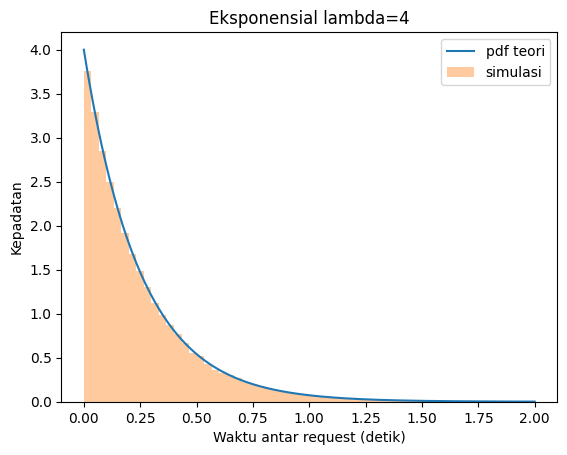


Interpretasi: Rata-rata jeda antar request 0.25 detik (1/4).
Peluang jeda lebih dari 0,5 detik 13.5%.
Median (0.173) lebih kecil dari rata-rata karena distribusi miring ke kanan.
Sifat tanpa memori terbukti: setelah menunggu 0,25 detik, peluang menunggu 0,5 detik lagi sama dengan semula.
Eksponensial (waktu antar kejadian) dan Poisson (jumlah kejadian) adalah dua sisi dari proses yang sama.


In [ ]:
lam = 4
E = st.expon(scale=1 / lam)
print(f"P(T>0.5) = {E.sf(0.5):.4f} (manual e^-2 = {math.exp(-2):.4f})")
print(f"P(T<0.1) = {E.cdf(0.1):.4f}")
print(f"E(T) = {E.mean():.3f} detik | Var(T) = {E.var():.4f} | median = {E.median():.4f} detik")
print(f"Tanpa memori: P(T>0.75 | T>0.25) = {E.sf(0.75)/E.sf(0.25):.4f} | P(T>0.5) = {E.sf(0.5):.4f}")

t_sym = sp.symbols("t", positive=True)
integral = sp.integrate(lam * sp.exp(-lam * t_sym), (t_sym, sp.Rational(1, 2), sp.oo))
print(f"Integral simbolik sympy P(T>0.5) = {integral} = {float(integral):.4f}")

sim = rng.exponential(1 / lam, 100000)
print(f"Simulasi: mean = {sim.mean():.4f} | P(T>0.5) = {(sim>0.5).mean():.4f}")

t = np.linspace(0, 2, 300)
plt.plot(t, E.pdf(t), label="pdf teori")
plt.hist(sim, bins=60, range=(0, 2), density=True, alpha=0.4, label="simulasi")
plt.title("Eksponensial lambda=4"); plt.xlabel("Waktu antar request (detik)"); plt.ylabel("Kepadatan"); plt.legend()
plt.show()

info(f"""Rata-rata jeda antar request {E.mean():.2f} detik (1/4).
Peluang jeda lebih dari 0,5 detik {E.sf(0.5):.1%}.
Median ({E.median():.3f}) lebih kecil dari rata-rata karena distribusi miring ke kanan.
Sifat tanpa memori terbukti: setelah menunggu 0,25 detik, peluang menunggu 0,5 detik lagi sama dengan semula.
Eksponensial (waktu antar kejadian) dan Poisson (jumlah kejadian) adalah dua sisi dari proses yang sama.""")

#### MATERI B2 - Distribusi Gamma
#### Studi kasus: waktu sampai request ke-3 (keluarga proses Poisson)
**Soal:** Dengan laju yang sama (λ = 4 request/detik), berapa peluang 3 request pertama sudah masuk dalam waktu kurang dari 1 detik? Waktu hingga request ke-3 berdistribusi Gamma(k = 3, θ = 1/λ).

Rumus: E(T) = k/λ, Var(T) = k/λ^2. Hubungan dengan Poisson: P(T<1) = P(N>=3), N ~ Poisson(4).

P(T<1)    = 0.7619
P(N>=3)   = 0.7619 (cek lewat Poisson)
E(T) = 0.750 detik | Var(T) = 0.1875
Simulasi jumlah 3 eksponensial: mean = 0.7497 | var = 0.1862 | P(T<1) = 0.7621


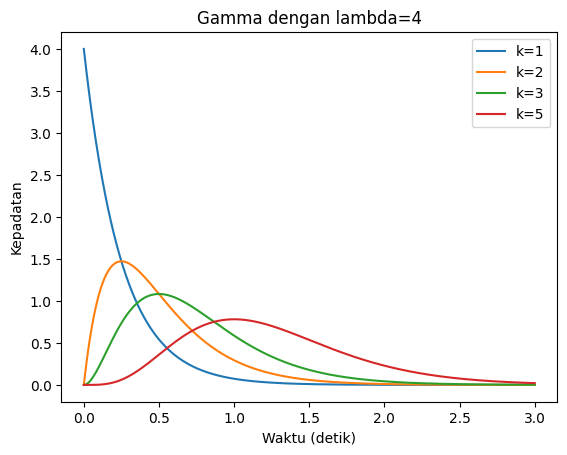


Interpretasi: Peluang 3 request masuk dalam 1 detik adalah 76.2%, sama persis dengan P(N>=3) dari Poisson, sehingga hubungan Gamma-Poisson terbukti.
Waktu rata-rata menunggu request ke-3 adalah 0.75 detik (3 x 0,25).
Gamma dengan k=1 adalah eksponensial, dan makin besar k kurvanya makin simetris.


In [ ]:
k, lam = 3, 4
Gm = st.gamma(a=k, scale=1 / lam)
print(f"P(T<1)    = {Gm.cdf(1):.4f}")
print(f"P(N>=3)   = {st.poisson(lam).sf(2):.4f} (cek lewat Poisson)")
print(f"E(T) = {Gm.mean():.3f} detik | Var(T) = {Gm.var():.4f}")

sim = rng.exponential(1 / lam, (100000, k)).sum(axis=1)
print(f"Simulasi jumlah 3 eksponensial: mean = {sim.mean():.4f} | var = {sim.var():.4f} | P(T<1) = {(sim<1).mean():.4f}")

t = np.linspace(0, 3, 300)
for kk in [1, 2, 3, 5]:
    plt.plot(t, st.gamma(a=kk, scale=1 / lam).pdf(t), label=f"k={kk}")
plt.title("Gamma dengan lambda=4"); plt.xlabel("Waktu (detik)"); plt.ylabel("Kepadatan"); plt.legend()
plt.show()

info(f"""Peluang 3 request masuk dalam 1 detik adalah {Gm.cdf(1):.1%}, sama persis dengan P(N>=3) dari Poisson, sehingga hubungan Gamma-Poisson terbukti.
Waktu rata-rata menunggu request ke-3 adalah {Gm.mean():.2f} detik (3 x 0,25).
Gamma dengan k=1 adalah eksponensial, dan makin besar k kurvanya makin simetris.""")

#### MATERI B3 - Distribusi Normal
#### Studi kasus: waktu respons API
**Soal:** Waktu respons sebuah API berdistribusi normal dengan rata-rata 200 ms dan simpangan baku 30 ms. Hitung P(X<250), P(170<X<230), P(X>260), persentil ke-95, dan z-score untuk 250 ms.

Rumus: z = (x - μ)/σ.

P(X<250)       = 0.9522
P(170<X<230)   = 0.6827
P(X>260)       = 0.0228
Persentil 95   = 249.35 ms
z-score 250 ms = 1.667
Simulasi: P(X<250) = 0.9514 | mean = 200.02 | std = 30.03


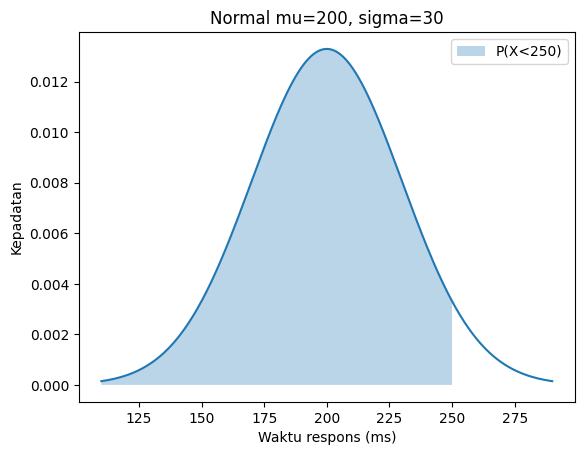


Interpretasi: Sebanyak 95.2% request selesai di bawah 250 ms, dan 95% selesai di bawah 249 ms.
Hanya 2.3% request lebih lambat dari 260 ms.
Sekitar 68% request berada pada rentang 170-230 ms (aturan empiris), sehingga bila target SLA 250 ms, sistem memenuhi sekitar 95% request, tetapi masih perlu diwaspadai ekor lambatnya.


In [ ]:
mu, sigma = 200, 30
N_ = st.norm(mu, sigma)
print(f"P(X<250)       = {N_.cdf(250):.4f}")
print(f"P(170<X<230)   = {N_.cdf(230) - N_.cdf(170):.4f}")
print(f"P(X>260)       = {N_.sf(260):.4f}")
print(f"Persentil 95   = {N_.ppf(0.95):.2f} ms")
print(f"z-score 250 ms = {(250 - mu) / sigma:.3f}")

sim = rng.normal(mu, sigma, 100000)
print(f"Simulasi: P(X<250) = {(sim<250).mean():.4f} | mean = {sim.mean():.2f} | std = {sim.std():.2f}")

x = np.linspace(110, 290, 400)
plt.plot(x, N_.pdf(x))
x_fill = np.linspace(110, 250, 200)
plt.fill_between(x_fill, N_.pdf(x_fill), alpha=0.3, label="P(X<250)")
plt.title("Normal mu=200, sigma=30"); plt.xlabel("Waktu respons (ms)"); plt.ylabel("Kepadatan"); plt.legend()
plt.show()

info(f"""Sebanyak {N_.cdf(250):.1%} request selesai di bawah 250 ms, dan 95% selesai di bawah {N_.ppf(0.95):.0f} ms.
Hanya {N_.sf(260):.1%} request lebih lambat dari 260 ms.
Sekitar 68% request berada pada rentang 170-230 ms (aturan empiris), sehingga bila target SLA 250 ms, sistem memenuhi sekitar 95% request, tetapi masih perlu diwaspadai ekor lambatnya.""")

#### MATERI B4 - Distribusi t
#### Studi kasus: rata-rata waktu eksekusi algoritma dari sampel kecil
**Soal:** Sebuah algoritma diuji 10 kali dan waktu eksekusinya (detik): 12,1; 11,8; 12,6; 12,3; 11,9; 12,8; 12,2; 12,0; 12,5; 12,4. Karena sampel kecil dan σ tidak diketahui, gunakan distribusi t. (a) Hitung selang kepercayaan 95% rata-rata. (b) Uji H0: μ = 12,0 detik.

Statistik uji: t = (x̄ - μ0) / (s / sqrt(n)), derajat bebas df = n - 1.

Cek library statistics: mean = 12.260 | stdev = 0.3204
n = 10 | rata-rata = 12.260 | s = 0.3204 | galat baku = 0.1013
t kritis (df=9, 95% dua sisi) = 2.262 | z kritis = 1.960
Selang kepercayaan 95% = (12.031, 12.489)

Uji t satu sampel: t = 2.566 | p-value = 0.0304


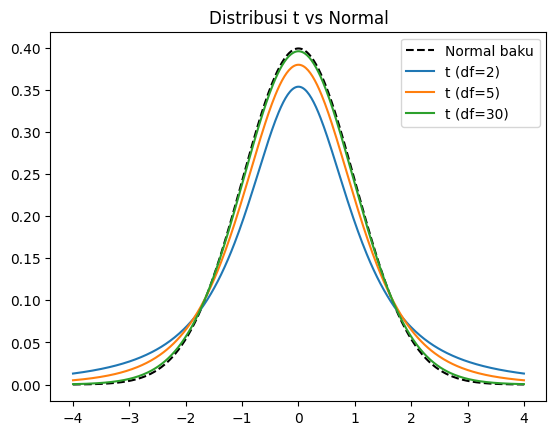


Interpretasi: Rata-rata waktu eksekusi 12.26 detik dengan selang kepercayaan 95% (12.03; 12.49).
Karena p-value 0.030 < 0,05, H0 (rata-rata 12,0 detik) ditolak; artinya algoritma ini rata-rata sedikit lebih lambat dari target 12,0 detik.
Nilai t kritis (2,262) lebih besar dari z kritis (1,96) sebagai kompensasi sampel kecil; dengan n=10, hasil ini layak tetapi sebaiknya dikonfirmasi dengan lebih banyak pengujian.


In [ ]:
data = np.array([12.1, 11.8, 12.6, 12.3, 11.9, 12.8, 12.2, 12.0, 12.5, 12.4])
n = len(data)
xbar, s = data.mean(), data.std(ddof=1)
print(f"Cek library statistics: mean = {stat.mean(data):.3f} | stdev = {stat.stdev(data):.4f}")
sem = s / math.sqrt(n)
ci = st.t.interval(0.95, df=n - 1, loc=xbar, scale=sem)
print(f"n = {n} | rata-rata = {xbar:.3f} | s = {s:.4f} | galat baku = {sem:.4f}")
print(f"t kritis (df=9, 95% dua sisi) = {st.t.ppf(0.975, n - 1):.3f} | z kritis = {st.norm.ppf(0.975):.3f}")
print(f"Selang kepercayaan 95% = ({ci[0]:.3f}, {ci[1]:.3f})")

hasil = st.ttest_1samp(data, popmean=12.0)
print(f"\nUji t satu sampel: t = {hasil.statistic:.3f} | p-value = {hasil.pvalue:.4f}")

x = np.linspace(-4, 4, 400)
plt.plot(x, st.norm.pdf(x), "k--", label="Normal baku")
for df in [2, 5, 30]:
    plt.plot(x, st.t.pdf(x, df), label=f"t (df={df})")
plt.title("Distribusi t vs Normal"); plt.legend(); plt.show()

keputusan = "ditolak" if hasil.pvalue < 0.05 else "tidak ditolak"
info(f"""Rata-rata waktu eksekusi {xbar:.2f} detik dengan selang kepercayaan 95% ({ci[0]:.2f}; {ci[1]:.2f}).
Karena p-value {hasil.pvalue:.3f} {'<' if hasil.pvalue < 0.05 else '>='} 0,05, H0 (rata-rata 12,0 detik) {keputusan}; artinya algoritma ini rata-rata sedikit lebih lambat dari target 12,0 detik.
Nilai t kritis (2,262) lebih besar dari z kritis (1,96) sebagai kompensasi sampel kecil; dengan n=10, hasil ini layak tetapi sebaiknya dikonfirmasi dengan lebih banyak pengujian.""")

#### MATERI B5 - Distribusi Chi-kuadrat
#### Studi kasus: kemerataan pembagian beban load balancer
**Soal:** Sebuah load balancer seharusnya membagi 1.000 request merata ke 4 server (harapan 250 per server). Dua log pengamatan: Skenario 1 = [265, 240, 270, 225], Skenario 2 = [330, 240, 250, 180]. Lakukan uji kecocokan chi-kuadrat dengan α = 5%.

Statistik: χ² = jumlah (O - E)^2 / E, df = k - 1 = 3.

Nilai kritis chi2 (df=3, alpha=5%) = 7.815

Skenario 1: observasi = [265, 240, 270, 225]
   chi2 manual = 5.40 | scipy = 5.40 | p-value = 0.144744 -> H0 tidak ditolak (merata)

Skenario 2: observasi = [330, 240, 250, 180]
   chi2 manual = 45.60 | scipy = 45.60 | p-value = 0.000000 -> H0 ditolak (tidak merata)



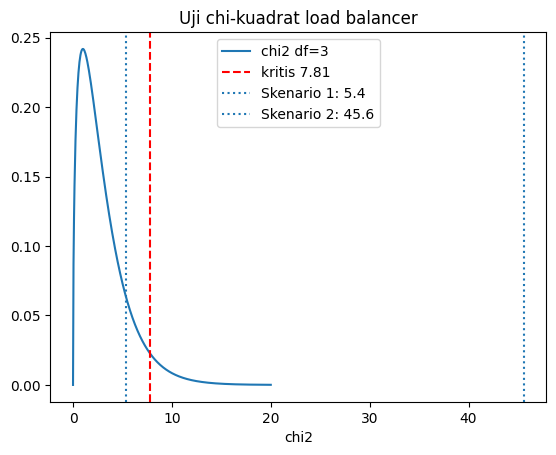


Interpretasi: Skenario 1 menghasilkan chi2 = 5.4 (< 7.81) dengan p-value 0.145, sehingga selisih dari 250 masih wajar sebagai fluktuasi acak: load balancer layak dan tergolong merata.

Skenario 2 menghasilkan chi2 = 45.6 (jauh di atas 7.81) dengan p-value sangat kecil, sehingga pembagian beban tidak merata dan konfigurasi load balancer perlu diperiksa.


In [ ]:
harapan = np.array([250, 250, 250, 250])
skenario = {"Skenario 1": [265, 240, 270, 225], "Skenario 2": [330, 240, 250, 180]}
kritis = st.chi2.ppf(0.95, df=3)
print(f"Nilai kritis chi2 (df=3, alpha=5%) = {kritis:.3f}\n")

hasil = {}
for nama, obs in skenario.items():
    chi2_manual = (((np.array(obs) - harapan) ** 2) / harapan).sum()
    res = st.chisquare(obs, f_exp=harapan)
    hasil[nama] = res
    putusan = "H0 ditolak (tidak merata)" if res.pvalue < 0.05 else "H0 tidak ditolak (merata)"
    print(f"{nama}: observasi = {obs}")
    print(f"   chi2 manual = {chi2_manual:.2f} | scipy = {res.statistic:.2f} | p-value = {res.pvalue:.6f} -> {putusan}\n")

x = np.linspace(0, 20, 400)
plt.plot(x, st.chi2.pdf(x, 3), label="chi2 df=3")
plt.axvline(kritis, color="red", linestyle="--", label=f"kritis {kritis:.2f}")
for nama, res in hasil.items():
    plt.axvline(res.statistic, linestyle=":", label=f"{nama}: {res.statistic:.1f}")
plt.legend(); plt.title("Uji chi-kuadrat load balancer"); plt.xlabel("chi2"); plt.show()

info(f"""Skenario 1 menghasilkan chi2 = {hasil['Skenario 1'].statistic:.1f} (< {kritis:.2f}) dengan p-value {hasil['Skenario 1'].pvalue:.3f}, sehingga selisih dari 250 masih wajar sebagai fluktuasi acak: load balancer layak dan tergolong merata.

Skenario 2 menghasilkan chi2 = {hasil['Skenario 2'].statistic:.1f} (jauh di atas {kritis:.2f}) dengan p-value sangat kecil, sehingga pembagian beban tidak merata dan konfigurasi load balancer perlu diperiksa.""")

#### MATERI B6 - Distribusi F
#### Studi kasus: variansi dua algoritma dan ANOVA tiga server
**Soal:** (a) Dua versi algoritma diuji: versi 1 (n=12) dengan varians waktu 9,0 dan versi 2 (n=10) dengan varians 4,0. Apakah variansnya berbeda? (b) Waktu respons (ms) dari 3 server diuji dengan ANOVA satu arah untuk membandingkan rata-ratanya.

Statistik: F = s1^2 / s2^2 dengan df (n1-1, n2-1). Pada ANOVA, F = rata-rata kuadrat antar kelompok / rata-rata kuadrat dalam kelompok.

(a) F = 9.0/4.0 = 2.250 | F kritis (df=11,9; 95%) = 3.102 | p-value (satu sisi) = 0.1168

(b) Rata-rata: A = 212.4, B = 228.0, C = 210.0
    ANOVA: F = 20.38 | p-value = 0.000138 | F kritis (df=2,12) = 3.885


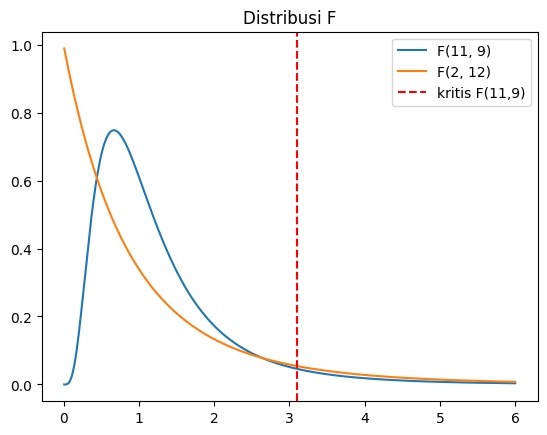


Interpretasi: (a) F = 2.25 lebih kecil dari F kritis 3.10 (p = 0.117 satu sisi; uji dua sisi p = 0.234), sehingga tidak cukup bukti bahwa variansi kedua versi berbeda.

(b) F ANOVA = 20.4 dengan p-value 0.000138 (< 0,05): rata-rata waktu respons ketiga server berbeda nyata.
Server B (rata-rata 228 ms) paling lambat dan perlu diselidiki.
Dengan hanya 5 sampel per server, kesimpulan ini layak sebagai indikasi awal.


In [ ]:
# (a) uji rasio varians
n1, n2, v1, v2 = 12, 10, 9.0, 4.0
F = v1 / v2
kritis = st.f.ppf(0.95, n1 - 1, n2 - 1)
p_val = st.f.sf(F, n1 - 1, n2 - 1)
print(f"(a) F = {v1}/{v2} = {F:.3f} | F kritis (df=11,9; 95%) = {kritis:.3f} | p-value (satu sisi) = {p_val:.4f}")

# (b) ANOVA
A = [210, 215, 205, 220, 212]
B = [225, 230, 222, 228, 235]
C = [208, 212, 210, 205, 215]
res = st.f_oneway(A, B, C)
print(f"\n(b) Rata-rata: A = {np.mean(A):.1f}, B = {np.mean(B):.1f}, C = {np.mean(C):.1f}")
print(f"    ANOVA: F = {res.statistic:.2f} | p-value = {res.pvalue:.6f} | F kritis (df=2,12) = {st.f.ppf(0.95, 2, 12):.3f}")

x = np.linspace(0.01, 6, 400)
plt.plot(x, st.f.pdf(x, 11, 9), label="F(11, 9)")
plt.plot(x, st.f.pdf(x, 2, 12), label="F(2, 12)")
plt.axvline(kritis, color="red", linestyle="--", label="kritis F(11,9)")
plt.legend(); plt.title("Distribusi F"); plt.show()

info(f"""(a) F = {F:.2f} lebih kecil dari F kritis {kritis:.2f} (p = {p_val:.3f} satu sisi; uji dua sisi p = {min(1, 2 * p_val):.3f}), sehingga tidak cukup bukti bahwa variansi kedua versi berbeda.

(b) F ANOVA = {res.statistic:.1f} dengan p-value {res.pvalue:.6f} (< 0,05): rata-rata waktu respons ketiga server berbeda nyata.
Server B (rata-rata 228 ms) paling lambat dan perlu diselidiki.
Dengan hanya 5 sampel per server, kesimpulan ini layak sebagai indikasi awal.""")

#### **BAGIAN C. EKSPLORASI TAMBAHAN**

#### EKSPLORASI C1 - Distribusi Bernoulli
#### Studi kasus: pengiriman satu paket data
**Soal:** Sebuah paket data dikirim melalui jaringan. Peluang paket sampai dengan sukses adalah 0,9. Tentukan P(X=1), P(X=0), E(X), Var(X), dan bandingkan dengan simulasi 100.000 pengiriman.
Bernoulli: satu percobaan dengan dua hasil, P(X=1) = p, P(X=0) = 1 - p, E(X) = p, Var(X) = p(1 - p).

In [ ]:
p = 0.9
X = st.bernoulli(p)
print(f"P(X=1) = {X.pmf(1):.2f} | P(X=0) = {X.pmf(0):.2f}")
print(f"E(X)   = {X.mean():.2f} | Var(X) = {X.var():.2f} (rumus p(1-p) = {p*(1-p):.2f})")

sim = rng.binomial(1, p, 100000)
print(f"Simulasi: rata-rata = {sim.mean():.4f} | varians = {sim.var():.4f}")

info(f"""Sebanyak {p:.0%} paket sampai, dan E(X) = {X.mean():.2f} sama dengan p.
Varians {X.var():.2f} kecil karena hasilnya hampir selalu sukses; varians Bernoulli terbesar (0,25) terjadi bila p = 0,5.
Simulasi sesuai dengan teori.""")

P(X=1) = 0.90 | P(X=0) = 0.10
E(X)   = 0.90 | Var(X) = 0.09 (rumus p(1-p) = 0.09)
Simulasi: rata-rata = 0.9013 | varians = 0.0890

Interpretasi: Sebanyak 90% paket sampai, dan E(X) = 0.90 sama dengan p.
Varians 0.09 kecil karena hasilnya hampir selalu sukses; varians Bernoulli terbesar (0,25) terjadi bila p = 0,5.
Simulasi sesuai dengan teori.


#### EKSPLORASI C2 - Distribusi Uniform Diskrit
#### Studi kasus: load balancer memilih 1 dari 4 server
**Soal:** Sebuah load balancer memilih 1 dari 4 server (nomor 1-4) secara acak merata. Hitung P(server 3), P(server <= 2), E(X), dan Var(X).

Rumus: P(X=x) = 1/n, E(X) = (a+b)/2, Var(X) = (n^2 - 1)/12.

In [ ]:
U = st.randint(1, 5)     # batas atas eksklusif -> nilai 1..4
print(f"P(X=3) = {U.pmf(3):.2f} | P(X<=2) = {U.cdf(2):.2f}")
print(f"E(X) = {U.mean():.2f} | Var(X) = {U.var():.4f} (rumus (4^2-1)/12 = {(4**2-1)/12:.4f})")
sim = rng.integers(1, 5, 100000)
print("Simulasi proporsi tiap server:", {s: round(float((sim == s).mean()), 3) for s in range(1, 5)})

info(f"""Tiap server mendapat 25% beban dalam jangka panjang, dan nomor server rata-rata {U.mean():.1f}.
Simulasi menunjukkan pembagian hampir merata, sehingga load balancer acak layak untuk beban yang homogen.""")

P(X=3) = 0.25 | P(X<=2) = 0.50
E(X) = 2.50 | Var(X) = 1.2500 (rumus (4^2-1)/12 = 1.2500)
Simulasi proporsi tiap server: {1: 0.251, 2: 0.251, 3: 0.249, 4: 0.25}

Interpretasi: Tiap server mendapat 25% beban dalam jangka panjang, dan nomor server rata-rata 2.5.
Simulasi menunjukkan pembagian hampir merata, sehingga load balancer acak layak untuk beban yang homogen.


#### EKSPLORASI C3 - Distribusi Uniform Kontinu
#### Studi kasus: jitter jaringan 0-10 ms
**Soal:** Jitter jaringan berdistribusi seragam antara 0 dan 10 ms. Hitung P(X<3), P(4<X<7), E(X), Var(X).

Rumus: f(x) = 1/(b-a), E(X) = (a+b)/2, Var(X) = (b-a)^2 / 12.

In [ ]:
Uc = st.uniform(loc=0, scale=10)
print(f"P(X<3) = {Uc.cdf(3):.2f} | P(4<X<7) = {Uc.cdf(7) - Uc.cdf(4):.2f}")
print(f"E(X) = {Uc.mean():.1f} | Var(X) = {Uc.var():.4f} (rumus 100/12 = {100/12:.4f})")
sim = rng.uniform(0, 10, 100000)
print(f"Simulasi: P(X<3) = {(sim<3).mean():.4f} | mean = {sim.mean():.3f}")

info(f"""Peluang jitter di bawah 3 ms adalah {Uc.cdf(3):.0%}, sebanding dengan panjang interval (3/10).
Rata-rata {Uc.mean():.0f} ms.
Semua nilai antara 0-10 ms sama mungkin; model ini cocok untuk delay acak (random backoff) tetapi kurang cocok untuk latensi nyata yang cenderung menumpuk di nilai kecil.""")

P(X<3) = 0.30 | P(4<X<7) = 0.30
E(X) = 5.0 | Var(X) = 8.3333 (rumus 100/12 = 8.3333)
Simulasi: P(X<3) = 0.3015 | mean = 4.994

Interpretasi: Peluang jitter di bawah 3 ms adalah 30%, sebanding dengan panjang interval (3/10).
Rata-rata 5 ms.
Semua nilai antara 0-10 ms sama mungkin; model ini cocok untuk delay acak (random backoff) tetapi kurang cocok untuk latensi nyata yang cenderung menumpuk di nilai kecil.


#### EKSPLORASI C4 - Distribusi Log-Normal
#### Studi kasus: durasi sesi pengguna
**Soal:** Durasi sesi pengguna (menit) berdistribusi log-normal dengan ln X ~ N(1; 0,8^2). Hitung median, rata-rata, dan P(X>10 menit).

Median = 2.718 menit (rumus e^mu = 2.718)
Rata-rata = 3.743 menit (rumus e^(mu+sigma^2/2) = 3.743)
P(X>10) = 0.0517
Simulasi: median = 2.721 | mean = 3.751 | P(X>10) = 0.0525


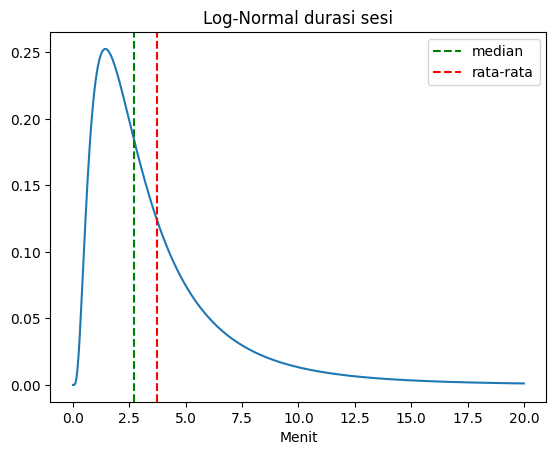


Interpretasi: Median sesi 2.7 menit tetapi rata-rata 3.7 menit karena segelintir sesi sangat panjang menarik rata-rata ke kanan.
Hanya 5.2% sesi lebih dari 10 menit.
Untuk data seperti ini median lebih layak dipakai sebagai ukuran 'sesi tipikal'.


In [ ]:
mu, sigma = 1.0, 0.8
L = st.lognorm(s=sigma, scale=math.exp(mu))
print(f"Median = {L.median():.3f} menit (rumus e^mu = {math.exp(mu):.3f})")
print(f"Rata-rata = {L.mean():.3f} menit (rumus e^(mu+sigma^2/2) = {math.exp(mu + sigma**2/2):.3f})")
print(f"P(X>10) = {L.sf(10):.4f}")
sim = rng.lognormal(mu, sigma, 100000)
print(f"Simulasi: median = {np.median(sim):.3f} | mean = {sim.mean():.3f} | P(X>10) = {(sim>10).mean():.4f}")

x = np.linspace(0, 20, 400)
plt.plot(x, L.pdf(x)); plt.axvline(L.median(), color="g", linestyle="--", label="median")
plt.axvline(L.mean(), color="r", linestyle="--", label="rata-rata"); plt.legend()
plt.title("Log-Normal durasi sesi"); plt.xlabel("Menit"); plt.show()

info(f"""Median sesi {L.median():.1f} menit tetapi rata-rata {L.mean():.1f} menit karena segelintir sesi sangat panjang menarik rata-rata ke kanan.
Hanya {L.sf(10):.1%} sesi lebih dari 10 menit.
Untuk data seperti ini median lebih layak dipakai sebagai ukuran 'sesi tipikal'.""")

#### EKSPLORASI C5 - Distribusi Weibull
#### Studi kasus: umur SSD server
**Soal:** Umur SSD server (tahun) mengikuti Weibull dengan bentuk k = 1,5 dan skala λ = 5. Hitung peluang SSD masih berfungsi setelah 3 tahun (reliabilitas), peluang rusak sebelum 2 tahun, dan umur rata-rata.

Rumus: R(t) = exp(-(t/λ)^k), E(T) = λ Γ(1 + 1/k).

R(3) = P(T>3)  = 0.6283 (manual 0.6283)
P(T<2)         = 0.2235
E(T) = 4.514 tahun (rumus 4.514) | Var(T) = 9.392


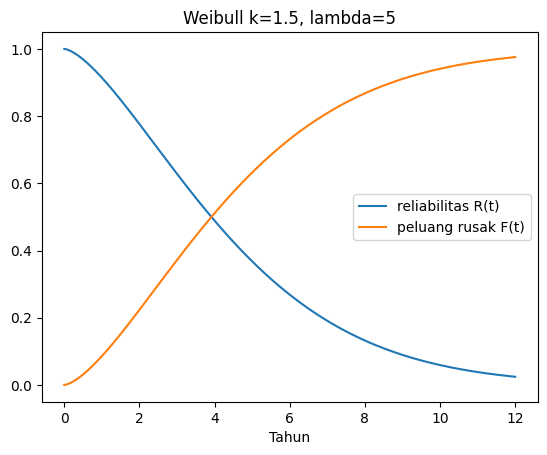


Interpretasi: Peluang SSD masih hidup setelah 3 tahun adalah 62.8%, dan peluang rusak sebelum 2 tahun 22.4%.
Umur rata-rata 4.5 tahun.
Karena k > 1, laju kerusakan naik seiring usia (wear-out), sehingga penggantian terjadwal sebelum tahun ke-4 layak dipertimbangkan.


In [ ]:
k, lam = 1.5, 5
W = st.weibull_min(c=k, scale=lam)
print(f"R(3) = P(T>3)  = {W.sf(3):.4f} (manual {math.exp(-(3/lam)**k):.4f})")
print(f"P(T<2)         = {W.cdf(2):.4f}")
print(f"E(T) = {W.mean():.3f} tahun (rumus {lam*math.gamma(1+1/k):.3f}) | Var(T) = {W.var():.3f}")

t = np.linspace(0, 12, 300)
plt.plot(t, W.sf(t), label="reliabilitas R(t)")
plt.plot(t, W.cdf(t), label="peluang rusak F(t)")
plt.title("Weibull k=1.5, lambda=5"); plt.xlabel("Tahun"); plt.legend(); plt.show()

info(f"""Peluang SSD masih hidup setelah 3 tahun adalah {W.sf(3):.1%}, dan peluang rusak sebelum 2 tahun {W.cdf(2):.1%}.
Umur rata-rata {W.mean():.1f} tahun.
Karena k > 1, laju kerusakan naik seiring usia (wear-out), sehingga penggantian terjadwal sebelum tahun ke-4 layak dipertimbangkan.""")

#### EKSPLORASI C6 - Distribusi Pareto
#### Studi kasus: ukuran file unduhan (heavy tail)
**Soal:** Ukuran file yang diunduh (MB) mengikuti Pareto dengan x_min = 1 dan α = 1,16. Hitung P(X>10), nilai rata-rata, dan seberapa besar kontribusi 20% file terbesar terhadap total trafik (aturan 80/20).

In [ ]:
alpha, xm = 1.16, 1
Pa = st.pareto(b=alpha, scale=xm)
print(f"P(X>10 MB) = {Pa.sf(10):.4f} (manual 10^-1.16 = {10**-alpha:.4f})")
print(f"E(X) = {Pa.mean():.3f} MB (rumus a.xm/(a-1) = {alpha*xm/(alpha-1):.3f}) | Var(X) = {Pa.var()}")

kontribusi_teori = 0.2 ** ((alpha - 1) / alpha)
print(f"Kontribusi teoritis 20% file terbesar = {kontribusi_teori:.3f}")

sim = np.sort(rng.pareto(alpha, 1000000) + 1)[::-1]
top20 = sim[: int(0.2 * len(sim))].sum() / sim.sum()
print(f"Simulasi 1.000.000 file: rata-rata = {sim.mean():.2f} MB | kontribusi top 20% = {top20:.3f}")

info(f"""Hanya {Pa.sf(10):.1%} file lebih besar dari 10 MB, tetapi 20% file terbesar menyumbang sekitar {kontribusi_teori:.0%} total trafik (aturan 80/20).
Varians tak hingga (inf) karena α < 2, sehingga rata-rata sampel tidak stabil: hasil simulasi bisa menyimpang jauh dari rata-rata teori (7,25 MB).
Implikasinya, kapasitas bandwidth tidak boleh dirancang berdasarkan rata-rata, tetapi berdasarkan ekor distribusi.""")

P(X>10 MB) = 0.0692 (manual 10^-1.16 = 0.0692)
E(X) = 7.250 MB (rumus a.xm/(a-1) = 7.250) | Var(X) = inf
Kontribusi teoritis 20% file terbesar = 0.801
Simulasi 1.000.000 file: rata-rata = 6.21 MB | kontribusi top 20% = 0.768

Interpretasi: Hanya 6.9% file lebih besar dari 10 MB, tetapi 20% file terbesar menyumbang sekitar 80% total trafik (aturan 80/20).
Varians tak hingga (inf) karena α < 2, sehingga rata-rata sampel tidak stabil: hasil simulasi bisa menyimpang jauh dari rata-rata teori (7,25 MB).
Implikasinya, kapasitas bandwidth tidak boleh dirancang berdasarkan rata-rata, tetapi berdasarkan ekor distribusi.


#### EKSPLORASI C7 - Distribusi Beta
#### Studi kasus: click-through rate iklan (pembaruan Bayes)
**Soal:** Sebuah iklan di aplikasi ditampilkan 50 kali dan diklik 8 kali. Dengan prior seragam Beta(1,1), tentukan distribusi posterior click-through rate (CTR), rata-rata, selang kredibel 95%, dan peluang CTR > 10%.

Posterior: Beta(1 + klik, 1 + tidak klik).

Posterior = Beta(9, 43)
Rata-rata CTR = 0.1731 | selang kredibel 95% = (0.0840, 0.2859)
P(CTR > 0.10) = 0.9357


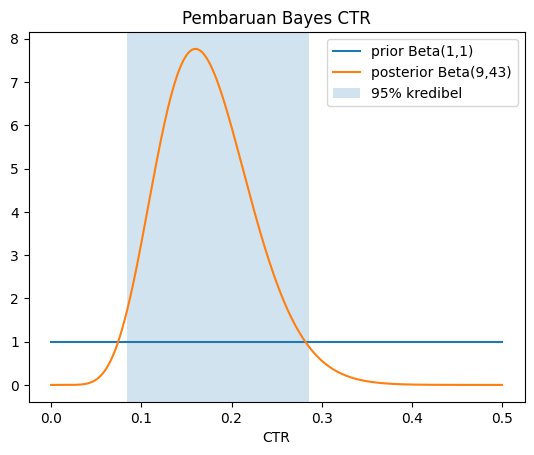


Interpretasi: Estimasi CTR sekitar 17.3% (8/50 = 16% mentah, ditarik sedikit ke prior).
Dengan keyakinan 95%, CTR sebenarnya antara 8.4% dan 28.6%.
Peluang CTR melebihi 10% adalah 93.6%.
Rentangnya masih lebar karena data hanya 50 tayangan, sehingga keputusan besar sebaiknya menunggu data lebih banyak.


In [ ]:
klik, tayang = 8, 50
a_post, b_post = 1 + klik, 1 + (tayang - klik)
Bt = st.beta(a_post, b_post)
lo, hi = Bt.interval(0.95)
print(f"Posterior = Beta({a_post}, {b_post})")
print(f"Rata-rata CTR = {Bt.mean():.4f} | selang kredibel 95% = ({lo:.4f}, {hi:.4f})")
print(f"P(CTR > 0.10) = {Bt.sf(0.10):.4f}")

x = np.linspace(0, 0.5, 400)
plt.plot(x, st.beta(1, 1).pdf(x), label="prior Beta(1,1)")
plt.plot(x, Bt.pdf(x), label=f"posterior Beta({a_post},{b_post})")
plt.axvspan(lo, hi, alpha=0.2, label="95% kredibel"); plt.legend()
plt.title("Pembaruan Bayes CTR"); plt.xlabel("CTR"); plt.show()

info(f"""Estimasi CTR sekitar {Bt.mean():.1%} (8/50 = 16% mentah, ditarik sedikit ke prior).
Dengan keyakinan 95%, CTR sebenarnya antara {lo:.1%} dan {hi:.1%}.
Peluang CTR melebihi 10% adalah {Bt.sf(0.10):.1%}.
Rentangnya masih lebar karena data hanya 50 tayangan, sehingga keputusan besar sebaiknya menunggu data lebih banyak.""")

#### EKSPLORASI C8 - Distribusi Zipf
#### Studi kasus: popularitas konten pada platform
**Soal:** Popularitas konten pada sebuah platform mengikuti Zipf dengan eksponen a = 2. Hitung peluang konten peringkat 1, 2, 3 dan peluang konten berada di peringkat 3 teratas.

In [ ]:
Z = st.zipf(a=2)
for r in [1, 2, 3]:
    print(f"P(peringkat {r}) = {Z.pmf(r):.4f}")
print(f"P(peringkat <= 3) = {Z.cdf(3):.4f}")
print(f"E(X) = {Z.mean()} (tak hingga untuk a <= 2)")
sim = rng.zipf(2, 100000)
print(f"Simulasi proporsi peringkat 1 = {(sim==1).mean():.4f}")

info(f"""Konten peringkat 1 menyerap {Z.pmf(1):.1%} dari seluruh akses dan tiga teratas {Z.cdf(3):.1%}.
Hasil ini khas pola long tail: sedikit konten sangat populer, sisanya jarang diakses.
Implikasi rekayasa: caching untuk konten teratas sudah menutup sebagian besar permintaan.""")

P(peringkat 1) = 0.6079
P(peringkat 2) = 0.1520
P(peringkat 3) = 0.0675
P(peringkat <= 3) = 0.8275
E(X) = inf (tak hingga untuk a <= 2)
Simulasi proporsi peringkat 1 = 0.6092

Interpretasi: Konten peringkat 1 menyerap 60.8% dari seluruh akses dan tiga teratas 82.7%.
Hasil ini khas pola long tail: sedikit konten sangat populer, sisanya jarang diakses.
Implikasi rekayasa: caching untuk konten teratas sudah menutup sebagian besar permintaan.


#### EKSPLORASI C9 - Distribusi Rayleigh
#### Studi kasus: amplitudo sinyal Wi-Fi yang mengalami fading
**Soal:** Amplitudo sinyal Wi-Fi pada ruangan padat mengikuti Rayleigh dengan parameter sigma = 2 (satuan relatif). Hitung peluang amplitudo melebihi 5, rata-rata, varians, dan modus.

Rumus: f(x) = (x/sigma^2) exp(-x^2/(2 sigma^2)), P(X>x) = exp(-x^2/(2 sigma^2)), E(X) = sigma sqrt(pi/2), Var(X) = (4 - pi)/2 sigma^2.

P(X>5) = 0.0439 (manual exp(-25/8) = 0.0439)
E(X) = 2.5066 (rumus sigma.sqrt(pi/2) = 2.5066)
Var(X) = 1.7168 (rumus (4-pi)/2.sigma^2 = 1.7168)
Modus = 2.0 | median = 2.3548
Simulasi: mean = 2.5075 | var = 1.7130 | P(X>5) = 0.0433


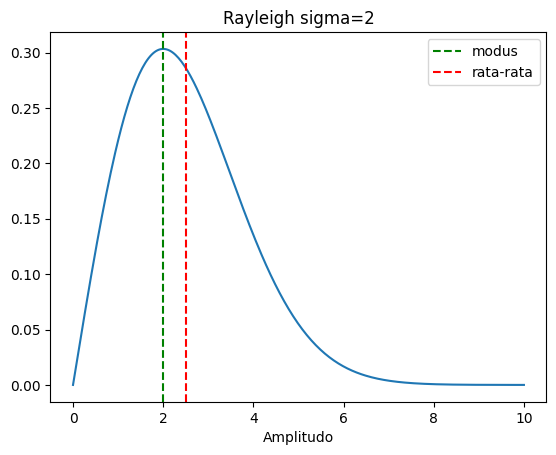


Interpretasi: Amplitudo paling sering sekitar 2 (modus), dengan rata-rata 2.51.
Hanya 4.4% sinyal melampaui amplitudo 5.
Rata-rata lebih besar dari modus karena ekor kanan lebih panjang.
Model ini layak untuk menggambarkan fading sinyal tanpa jalur langsung (non line-of-sight).


In [ ]:
sigma = 2.0
R = st.rayleigh(scale=sigma)
print(f"P(X>5) = {R.sf(5):.4f} (manual exp(-25/8) = {math.exp(-25/(2*sigma**2)):.4f})")
print(f"E(X) = {R.mean():.4f} (rumus sigma.sqrt(pi/2) = {sigma*math.sqrt(math.pi/2):.4f})")
print(f"Var(X) = {R.var():.4f} (rumus (4-pi)/2.sigma^2 = {(4-math.pi)/2*sigma**2:.4f})")
print(f"Modus = {sigma} | median = {R.median():.4f}")

sim = rng.rayleigh(sigma, 100000)
print(f"Simulasi: mean = {sim.mean():.4f} | var = {sim.var():.4f} | P(X>5) = {(sim>5).mean():.4f}")

x = np.linspace(0, 10, 300)
plt.plot(x, R.pdf(x)); plt.axvline(sigma, color="g", linestyle="--", label="modus")
plt.axvline(R.mean(), color="r", linestyle="--", label="rata-rata"); plt.legend()
plt.title("Rayleigh sigma=2"); plt.xlabel("Amplitudo"); plt.show()

info(f"""Amplitudo paling sering sekitar {sigma:.0f} (modus), dengan rata-rata {R.mean():.2f}.
Hanya {R.sf(5):.1%} sinyal melampaui amplitudo 5.
Rata-rata lebih besar dari modus karena ekor kanan lebih panjang.
Model ini layak untuk menggambarkan fading sinyal tanpa jalur langsung (non line-of-sight).""")

#### EKSPLORASI C10 - Distribusi Laplace
#### Studi kasus: derau pada mekanisme differential privacy
**Soal:** Sebuah basis data menambahkan derau Laplace agar hasil kueri bersifat privat. Dengan sensitivitas 1 dan epsilon 0,5, skala derau b = 1/0,5 = 2. Hitung varians derau, peluang |derau| > 3, dan bandingkan ketebalan ekor dengan Normal yang variansnya sama.

Rumus: f(x) = (1/2b) exp(-|x - mu|/b), E(X) = mu, Var(X) = 2b^2, P(|X|>a) = exp(-a/b).

b = 2.0 | E(X) = 0.0 | Var(X) = 8.0 (rumus 2b^2 = 8.0)
P(|X|>3): Laplace = 0.2231 (manual exp(-3/2) = 0.2231) | Normal (varians sama) = 0.2888
P(|X|>8): Laplace = 0.0183 (manual exp(-8/2) = 0.0183) | Normal (varians sama) = 0.0047
Simulasi: var = 7.899 | P(|X|>3) = 0.2207


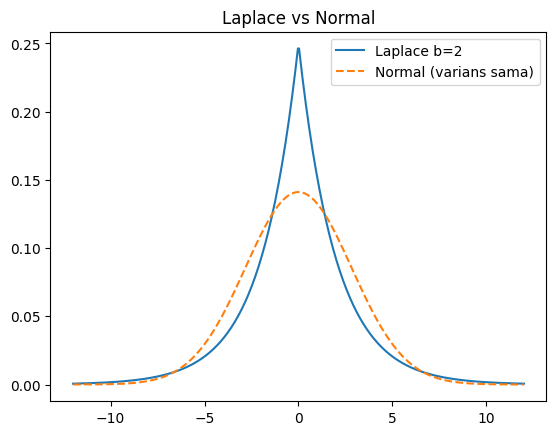


Interpretasi: Derau rata-rata nol dengan simpangan baku 2.83.
Puncak Laplace lebih runcing dan ekornya lebih tebal dibanding Normal: peluang derau lebih dari 8 adalah 1.83% versus 0.47% pada Normal.
Semakin kecil epsilon, semakin besar b dan derau, sehingga privasi naik tetapi akurasi hasil kueri turun.


In [ ]:
eps, sens = 0.5, 1.0
b = sens / eps
La = st.laplace(loc=0, scale=b)
print(f"b = {b} | E(X) = {La.mean():.1f} | Var(X) = {La.var():.1f} (rumus 2b^2 = {2*b*b:.1f})")

normal_sama = st.norm(0, math.sqrt(La.var()))
for a in [3, 8]:
    print(f"P(|X|>{a}): Laplace = {2*La.sf(a):.4f} (manual exp(-{a}/{b:.0f}) = {math.exp(-a/b):.4f}) | Normal (varians sama) = {2*normal_sama.sf(a):.4f}")

sim = rng.laplace(0, b, 100000)
print(f"Simulasi: var = {sim.var():.3f} | P(|X|>3) = {(abs(sim)>3).mean():.4f}")

x = np.linspace(-12, 12, 400)
plt.plot(x, La.pdf(x), label="Laplace b=2"); plt.plot(x, normal_sama.pdf(x), "--", label="Normal (varians sama)")
plt.legend(); plt.title("Laplace vs Normal"); plt.show()

info(f"""Derau rata-rata nol dengan simpangan baku {math.sqrt(La.var()):.2f}.
Puncak Laplace lebih runcing dan ekornya lebih tebal dibanding Normal: peluang derau lebih dari 8 adalah {2*La.sf(8):.2%} versus {2*normal_sama.sf(8):.2%} pada Normal.
Semakin kecil epsilon, semakin besar b dan derau, sehingga privasi naik tetapi akurasi hasil kueri turun.""")

#### EKSPLORASI C11 - Distribusi Cauchy
#### Studi kasus: lonjakan latensi dengan rata-rata yang tidak ada
**Soal:** Selisih waktu antar dua log server (terstandar) diduga berdistribusi Cauchy standar. Hitung P(X>10), P(|X|<1), median, lalu amati apakah rata-rata sampel menjadi stabil seperti pada Normal.

Cauchy memiliki median tetapi tidak memiliki rata-rata maupun varians (tak terdefinisi).

P(X>10)  = 0.0317 (manual 0.5 - atan(10)/pi = 0.0317)
P(|X|<1) = 0.5000
Median = 0.0 | E(X) = nan | Var(X) = nan  (nan = tidak terdefinisi)
n =    100: rata-rata sampel Cauchy =  -0.9627 | Normal =   0.0938
n =  10000: rata-rata sampel Cauchy =   0.8091 | Normal =  -0.0024
n = 100000: rata-rata sampel Cauchy =  -0.4198 | Normal =   0.0005


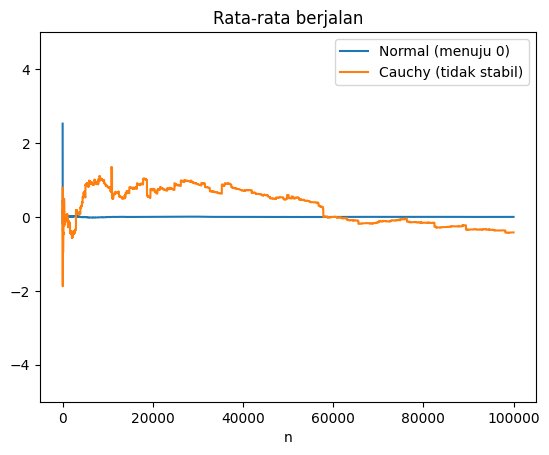


Interpretasi: Rata-rata sampel Normal mengerucut ke 0, sedangkan rata-rata Cauchy terus melonjak walau n sangat besar, sebab nilai ekstrem sesekali menarik rata-rata.
Peluang nilai ekstrem (X>10) tetap 3.2%.
Untuk data berekor sangat berat seperti ini, gunakan median atau ukuran robust, jangan rata-rata.


In [ ]:
C = st.cauchy(loc=0, scale=1)
print(f"P(X>10)  = {C.sf(10):.4f} (manual 0.5 - atan(10)/pi = {0.5 - math.atan(10)/math.pi:.4f})")
print(f"P(|X|<1) = {C.cdf(1) - C.cdf(-1):.4f}")
print(f"Median = {C.median()} | E(X) = {C.mean()} | Var(X) = {C.var()}  (nan = tidak terdefinisi)")

N_ = 100000
rata_cauchy = np.cumsum(rng.standard_cauchy(N_)) / np.arange(1, N_ + 1)
rata_normal = np.cumsum(rng.standard_normal(N_)) / np.arange(1, N_ + 1)
for n in [100, 10000, 100000]:
    print(f"n = {n:>6}: rata-rata sampel Cauchy = {rata_cauchy[n-1]:>8.4f} | Normal = {rata_normal[n-1]:>8.4f}")

plt.plot(rata_normal, label="Normal (menuju 0)")
plt.plot(rata_cauchy, label="Cauchy (tidak stabil)")
plt.ylim(-5, 5); plt.legend(); plt.title("Rata-rata berjalan"); plt.xlabel("n"); plt.show()

info(f"""Rata-rata sampel Normal mengerucut ke 0, sedangkan rata-rata Cauchy terus melonjak walau n sangat besar, sebab nilai ekstrem sesekali menarik rata-rata.
Peluang nilai ekstrem (X>10) tetap {C.sf(10):.1%}.
Untuk data berekor sangat berat seperti ini, gunakan median atau ukuran robust, jangan rata-rata.""")

#### **BAGIAN D. HUBUNGAN ANTAR DISTRIBUSI DAN REKAP**

#### REKAP D1 - Poisson dan Normal sebagai Pendekatan Binomial
**Soal:** (a) Dari n = 1000 paket, peluang tiap paket rusak p = 0,002. Bandingkan Binomial(1000; 0,002) dengan Poisson(λ = 2). (b) Untuk Binomial(100; 0,5), bandingkan P(X<=55) eksak dengan pendekatan Normal (dengan koreksi kontinuitas).

 x  Binomial  Poisson(2)  Selisih
 0    0.1351      0.1353   0.0003
 1    0.2707      0.2707   0.0000
 2    0.2709      0.2707   0.0003
 3    0.1806      0.1804   0.0002
 4    0.0902      0.0902   0.0000
 5    0.0360      0.0361   0.0001
 6    0.0120      0.0120   0.0001

(b) P(X<=55) eksak = 0.8644 | pendekatan Normal = 0.8643 | selisih = 0.0000


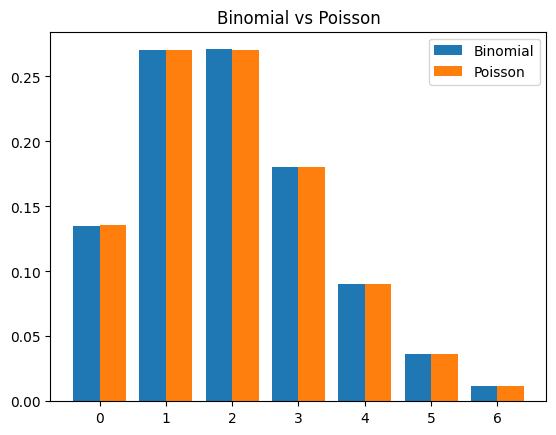


Interpretasi: Selisih terbesar Binomial dan Poisson hanya 0.00027, sehingga untuk n besar dan p kecil, Poisson layak sebagai pengganti Binomial yang lebih mudah dihitung.

Pada (b), pendekatan Normal berselisih 0.0000 dari nilai eksak, cukup akurat untuk n besar dan p tidak ekstrem.


In [ ]:
n, p = 1000, 0.002
xs = np.arange(0, 7)
tb = pd.DataFrame({"x": xs, "Binomial": st.binom.pmf(xs, n, p), "Poisson(2)": st.poisson.pmf(xs, n * p)})
tb["Selisih"] = (tb["Binomial"] - tb["Poisson(2)"]).abs()
print(tb.to_string(index=False))

n2, p2 = 100, 0.5
eksak = st.binom.cdf(55, n2, p2)
aprox = st.norm.cdf(55.5, n2 * p2, math.sqrt(n2 * p2 * (1 - p2)))
print(f"\n(b) P(X<=55) eksak = {eksak:.4f} | pendekatan Normal = {aprox:.4f} | selisih = {abs(eksak-aprox):.4f}")

plt.bar(xs - 0.2, tb["Binomial"], width=0.4, label="Binomial")
plt.bar(xs + 0.2, tb["Poisson(2)"], width=0.4, label="Poisson")
plt.legend(); plt.title("Binomial vs Poisson"); plt.show()

info(f"""Selisih terbesar Binomial dan Poisson hanya {tb['Selisih'].max():.5f}, sehingga untuk n besar dan p kecil, Poisson layak sebagai pengganti Binomial yang lebih mudah dihitung.

Pada (b), pendekatan Normal berselisih {abs(eksak-aprox):.4f} dari nilai eksak, cukup akurat untuk n besar dan p tidak ekstrem.""")

#### REKAP D2 - Nilai Harapan dan Varians Seluruh Distribusi
**Soal:** Hitung E(X) dan Var(X) semua distribusi yang dipakai dengan parameter pada kasus di atas, lalu bandingkan.

In [ ]:
daftar = {
    "Bernoulli(0.9)": st.bernoulli(0.9),
    "Hipergeometrik(12,2,6)": st.hypergeom(12, 2, 6),
    "Binomial(5,0.25)": st.binom(5, 0.25),
    "Geometrik(0.2)": st.geom(0.2),
    "Binomial Negatif(3,0.3) [jumlah gagal]": st.nbinom(3, 0.3),
    "Poisson(4)": st.poisson(4),
    "Uniform diskrit(1..4)": st.randint(1, 5),
    "Eksponensial(lambda=4)": st.expon(scale=0.25),
    "Gamma(k=3, lambda=4)": st.gamma(3, scale=0.25),
    "Normal(200,30)": st.norm(200, 30),
    "t(df=9)": st.t(9),
    "Chi-kuadrat(df=3)": st.chi2(3),
    "F(11,9)": st.f(11, 9),
    "Uniform kontinu(0,10)": st.uniform(0, 10),
    "Log-Normal(1,0.8)": st.lognorm(0.8, scale=math.exp(1)),
    "Weibull(1.5,5)": st.weibull_min(1.5, scale=5),
    "Beta(9,43)": st.beta(9, 43),
    "Rayleigh(sigma=2)": st.rayleigh(scale=2),
    "Laplace(0,2)": st.laplace(0, 2),
}
baris = []
for nama, d in daftar.items():
    m, v = d.stats(moments="mv")
    baris.append({"Distribusi": nama, "E(X)": float(m), "Var(X)": float(v)})
print(pd.DataFrame(baris).to_string(index=False))

info(f"""Tabel ini menunjukkan bahwa setiap distribusi punya rata-rata dan varians dengan rumus tertutup.
Poisson memiliki E = Var (4 = 4), Eksponensial memiliki E = 1/lambda, dan Gamma menjumlahkan k eksponensial (E = 3 x 0,25 = 0,75).
Binomial Negatif pada tabel menghitung jumlah gagal (E = 7), sehingga jumlah percobaannya 7 + 3 = 10, sama dengan Materi A4.
Varians Log-Normal jauh lebih besar dari rata-ratanya, menandakan ekor kanan yang panjang.
Distribusi Multinomial, Pareto, Zipf, dan Cauchy tidak dimasukkan karena bersifat vektor atau variansnya tak hingga/tak terdefinisi pada parameter yang dipakai.""")

                            Distribusi     E(X)   Var(X)
                        Bernoulli(0.9)   0.9000   0.0900
                Hipergeometrik(12,2,6)   1.0000   0.4545
                      Binomial(5,0.25)   1.2500   0.9375
                        Geometrik(0.2)   5.0000  20.0000
Binomial Negatif(3,0.3) [jumlah gagal]   7.0000  23.3333
                            Poisson(4)   4.0000   4.0000
                 Uniform diskrit(1..4)   2.5000   1.2500
                Eksponensial(lambda=4)   0.2500   0.0625
                  Gamma(k=3, lambda=4)   0.7500   0.1875
                        Normal(200,30) 200.0000 900.0000
                               t(df=9)   0.0000   1.2857
                     Chi-kuadrat(df=3)   3.0000   6.0000
                               F(11,9)   1.2857   1.0820
                 Uniform kontinu(0,10)   5.0000   8.3333
                     Log-Normal(1,0.8)   3.7434  12.5626
                        Weibull(1.5,5)   4.5137   9.3923
                            Bet